# 01 - Data setup

This notebook checks that the downloaded pill images are in the right folders and that the counts match the dataset. It then splits the normal training images into a shared training set and a validation set for the rest of the team.

## Steps

1. Confirm the images are under `data/pill/train/good/`, `data/pill/test/`, and `data/pill/ground_truth/`, and leave the original folder names unchanged.
2. Count the images and compare them with the published numbers: 267 normal training images, 26 normal test images, and 141 defective test images. Also check that the images are 800 × 800.
3. Check that all images are RGB and look for duplicate images.
4. Look at a few normal training images to confirm the download looks right.
5. Check that every defective test image has a matching ground-truth mask. Do not score the masks here.
6. Split only the normal training images, before making patches or extra copies of the images. The plan is about 214 training images and 53 validation images. If the count is not 267, stop and agree on the split before continuing.
7. Write those paths to `split.csv`. Each path is relative to `data/pill/`, and each row is labeled `train` or `val`.
8. Leave the official test set out of `split.csv`. Test labels and defect masks are reserved for notebook 04.


### 01 - Data Setup

This notebook checks the MVTec AD pill dataset to make sure the images are downloaded correctly and organized in the required folders.

It verifies image counts, image dimensions, and ground-truth masks. It then splits the 267 normal training images into a shared training set and validation set for the project team.

The official test images are kept separate and will only be used for model evaluation.

In [1]:
# Import libraries
from pathlib import Path
import csv
import random
import hashlib
import matplotlib.pyplot as plt
from PIL import Image


### 1. Check Dataset Folders

First, check that the downloaded pill dataset is located in the correct folders. The original folder names are kept unchanged.

In [2]:
# Set the main dataset folder
DATA_DIR = Path("../data/pill")

# Define the required folders
train_folder = DATA_DIR / "train" / "good"
test_folder = DATA_DIR / "test"
mask_folder = DATA_DIR / "ground_truth"

# Check that all required folders exist
required_folders = [train_folder, test_folder, mask_folder]

for folder in required_folders:
    print(folder, "exists:", folder.exists())

../data/pill/train/good exists: True
../data/pill/test exists: True
../data/pill/ground_truth exists: True


### 2. Count Dataset Images

Count the normal training images, normal test images, and defective test images. Compare the results with the published MVTec AD dataset counts.

In [3]:
# Count normal training images
train_images = list(train_folder.glob("*.png"))

# Count normal test images
normal_test_images = list((test_folder / "good").glob("*.png"))

# Count defective test images
defect_categories = [
    folder for folder in test_folder.iterdir()
    if folder.is_dir() and folder.name != "good"
]

defective_images = []

for folder in defect_categories:
    defective_images.extend(folder.glob("*.png"))

# Display the counts
print("Normal training images:", len(train_images))
print("Normal test images:", len(normal_test_images))
print("Defective test images:", len(defective_images))
print("Total defective categories:", len(defect_categories))

Normal training images: 267
Normal test images: 26
Defective test images: 141
Total defective categories: 7


### 2.2 Check Image Dimensions

The original MVTec AD pill images are 800 × 800 pixels. Check the image dimensions to make sure the dataset downloaded correctly.

In [4]:
# Check dimensions of all dataset images
all_images = train_images + normal_test_images + defective_images

incorrect_dimensions = []

for image_path in all_images:
    with Image.open(image_path) as image:
        if image.size != (800, 800):
            incorrect_dimensions.append(image_path)

print("Total images checked:", len(all_images))
print("Images with incorrect dimensions:", len(incorrect_dimensions))

Total images checked: 434
Images with incorrect dimensions: 0


### 3. Check Image Color Mode

Check that all images are RGB so they have the expected three color channels for the autoencoder models.

In [5]:
# Check that all images are RGB
non_rgb_images = []

for image_path in all_images:
    with Image.open(image_path) as image:
        if image.mode != "RGB":
            non_rgb_images.append(image_path)

print("Total images checked:", len(all_images))
print("Images that are not RGB:", len(non_rgb_images))

Total images checked: 434
Images that are not RGB: 0


### 3.2 Check for Duplicate Images

Check for exact duplicate image files. This helps identify whether the same image appears more than once in the dataset.

In [6]:
# Create a hash for each image
image_hashes = []

for image_path in all_images:
    with open(image_path, "rb") as file:
        image_hashes.append(hashlib.md5(file.read()).hexdigest())

# Count unique images and duplicates
unique_images = len(set(image_hashes))
duplicate_images = len(image_hashes) - unique_images

print("Total images:", len(image_hashes))
print("Unique images:", unique_images)
print("Duplicate images:", duplicate_images)

Total images: 434
Unique images: 434
Duplicate images: 0


### 4. View Sample Normal Images

Display a few normal training images to visually confirm that the dataset downloaded correctly.

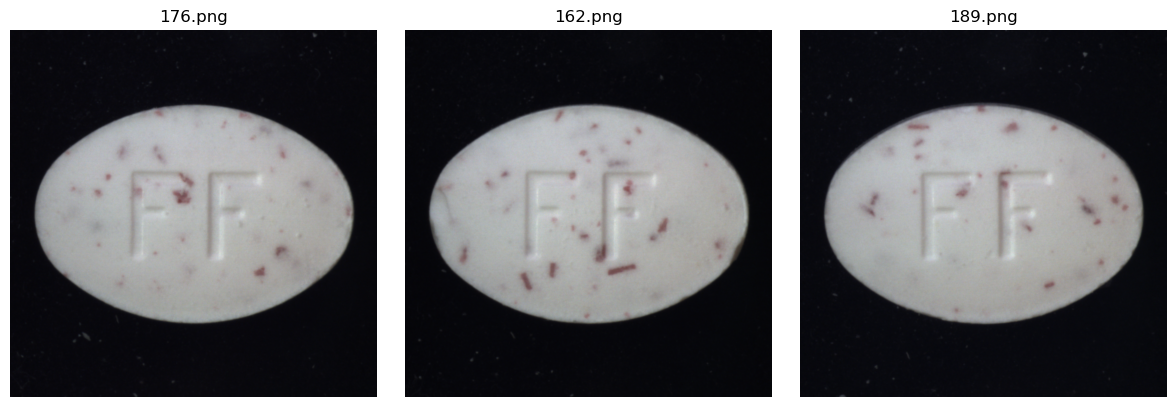

In [7]:
# Display three normal pill images
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, image_path in zip(axes, train_images[:3]):
    image = Image.open(image_path)
    ax.imshow(image)
    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 5. Check Ground-Truth Masks

Check that every defective test image has a corresponding ground-truth mask. The masks identify the actual defective areas and will be used later for model evaluation.


In [8]:
# Check that each defective image has a matching mask
missing_masks = []

for image_path in defective_images:
    category = image_path.parent.name
    mask_path = mask_folder / category / f"{image_path.stem}_mask.png"

    if not mask_path.exists():
        missing_masks.append(image_path)

print("Defective images checked:", len(defective_images))
print("Missing ground-truth masks:", len(missing_masks))

Defective images checked: 141
Missing ground-truth masks: 0


### 6. Create Training and Validation Split

Split the 267 normal training images into a training set and a validation set.

Approximately 80% of the images will be used for training and 20% for validation. A fixed random seed is used to make the split reproducible.

Only the original normal training images are included. The official test images and ground-truth masks are excluded.

In [9]:
# Check that there are exactly 267 normal training images
if len(train_images) != 267:
    raise ValueError("Expected 267 normal training images. Stop and verify the dataset.")

# Shuffle images using a fixed random seed
random.seed(42)
shuffled_images = sorted(train_images)
random.shuffle(shuffled_images)

# Split into training and validation sets
training_set = shuffled_images[:214]
validation_set = shuffled_images[214:]

print("Training images:", len(training_set))
print("Validation images:", len(validation_set))

Training images: 214
Validation images: 53


### 7. Save Shared Split

Save the training and validation assignments to *split.csv*. Each image path is relative to the *data/pill* folder so that the other team members can use the same assignments.

In [10]:
# Create the split.csv file
split_file = Path("../split.csv")

with open(split_file, "w", newline="") as file:
    writer = csv.writer(file)

    writer.writerow(["relative_path", "split"])

    for image_path in training_set:
        relative_path = image_path.relative_to(DATA_DIR)
        writer.writerow([relative_path.as_posix(), "train"])

    for image_path in validation_set:
        relative_path = image_path.relative_to(DATA_DIR)
        writer.writerow([relative_path.as_posix(), "val"])

print("Split saved to:", split_file)

Split saved to: ../split.csv


### 8. Verify Final Split

Read the saved *split.csv* file and verify that it contains the correct number of training and validation images. Confirm that only normal training images were included.

In [11]:
# Read and verify the saved split
with open(split_file, "r") as file:
    rows = list(csv.DictReader(file))

train_count = sum(row["split"] == "train" for row in rows)
val_count = sum(row["split"] == "val" for row in rows)

print("Total assigned images:", len(rows))
print("Training images:", train_count)
print("Validation images:", val_count)

# Check that all paths point to normal training images
correct_paths = all(
    row["relative_path"].startswith("train/good/")
    for row in rows
)

print("Only normal training images included:", correct_paths)

Total assigned images: 267
Training images: 214
Validation images: 53
Only normal training images included: True
